In [4]:
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from PIL import Image

import pandas as pd
import numpy as np

from pathlib import Path

import matplotlib.pyplot as plt

In [5]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")

Device: cpu
GPU not available. Using CPU.


In [6]:
cwd = Path.cwd()

if (cwd / "results").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "results").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(
        "Project root not found."
    )

RESULTS_DIR = PROJECT_ROOT / "results"

print("Project root:", PROJECT_ROOT)
print("Results directory:", RESULTS_DIR)

Project root: c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\notebooks
Results directory: c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\notebooks\results


In [7]:
cwd = Path.cwd()

if (cwd / "results").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "results").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(
        "Project root not found."
    )

RESULTS_DIR = PROJECT_ROOT / "results"

print("Project root:", PROJECT_ROOT)
print("Results directory:", RESULTS_DIR)

Project root: c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\notebooks
Results directory: c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\notebooks\results


In [8]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
RESULTS_DIR = PROJECT_ROOT / "results"

print("Project root:", PROJECT_ROOT)
print("Results folder:", RESULTS_DIR)


Project root: c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION
Results folder: c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\results


In [9]:
#load final data 
#pytorch dataset loading
metadata_path = RESULTS_DIR / "final_face_metadata.csv"

if not metadata_path.exists():
    raise FileNotFoundError(
        f"File not found: {metadata_path}"
    )

face_metadata_df = pd.read_csv(metadata_path)

print("Total face images:", len(face_metadata_df))
display(face_metadata_df.head())

Total face images: 61641


,video_path,video_id,face_path,label,class_name,file_exists,image_size,split
0,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,id0_0000,results\processed_faces\real\id0_0000_face_00.jpg,0,real,True,"(224, 224)",train
1,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,id0_0000,results\processed_faces\real\id0_0000_face_01.jpg,0,real,True,"(224, 224)",train
2,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,id0_0000,results\processed_faces\real\id0_0000_face_02.jpg,0,real,True,"(224, 224)",train
3,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,id0_0000,results\processed_faces\real\id0_0000_face_03.jpg,0,real,True,"(224, 224)",train
4,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,id0_0000,results\processed_faces\real\id0_0000_face_04.jpg,0,real,True,"(224, 224)",train


In [11]:
# check split
print(
    face_metadata_df["split"].value_counts()
)

print("\nClass distribution:")
print(
    face_metadata_df["class_name"].value_counts()
)

split
train    39450
test     12321
val       9870
Name: count, dtype: int64

Class distribution:
class_name
deepfake    53030
real         8611
Name: count, dtype: int64


In [10]:
#verify image files
face_metadata_df["file_exists"] = face_metadata_df[
    "face_path"
].apply(
    lambda x: (PROJECT_ROOT / x).exists()
)

print(
    face_metadata_df["file_exists"].value_counts()
)

file_exists
True    61641
Name: count, dtype: int64


In [12]:
#remove missing images
face_metadata_df = face_metadata_df[
    face_metadata_df["file_exists"]
].copy()

face_metadata_df = face_metadata_df.drop(
    columns=["file_exists"]
)

print("Valid images:", len(face_metadata_df))


Valid images: 61641


In [13]:
#Train/Validation/Test DataFrames
train_df = face_metadata_df[
    face_metadata_df["split"] == "train"
].reset_index(drop=True)

val_df = face_metadata_df[
    face_metadata_df["split"] == "val"
].reset_index(drop=True)

test_df = face_metadata_df[
    face_metadata_df["split"] == "test"
].reset_index(drop=True)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 39450
Validation: 9870
Test: 12321


In [14]:
# transform
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])


#validation/test
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])



In [15]:
# dataset class
class DeepfakeDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        image_path = PROJECT_ROOT / row["face_path"]

        image = Image.open(image_path).convert("RGB")

        label = int(row["label"])

        if self.transform:
            image = self.transform(image)

        return image, label

In [16]:
#create datasets
train_dataset = DeepfakeDataset(
    train_df,
    train_transform
)

val_dataset = DeepfakeDataset(
    val_df,
    test_transform
)

test_dataset = DeepfakeDataset(
    test_df,
    test_transform
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 39450
Validation dataset: 9870
Test dataset: 12321


In [17]:
#dataLoader
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

In [18]:
#check one batch 
images, labels = next(iter(train_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Labels:", labels[:10])

Images: torch.Size([32, 3, 224, 224])
Labels: torch.Size([32])
Labels: tensor([1, 0, 1, 0, 1, 1, 1, 1, 1, 1])


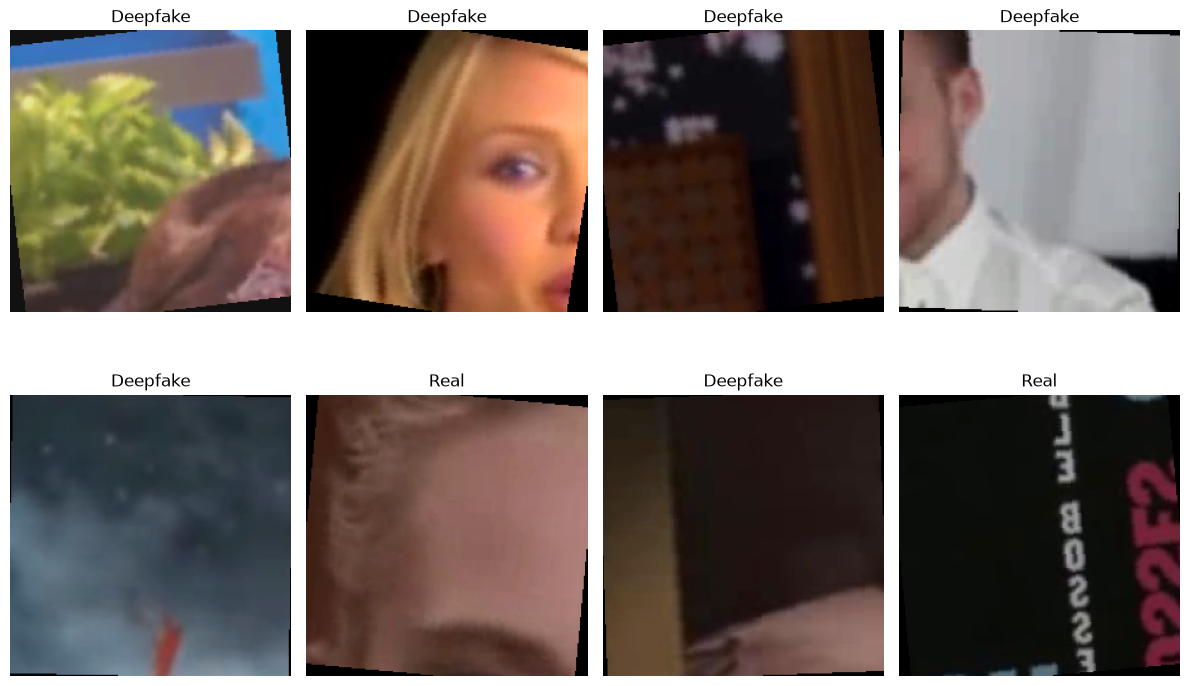

In [19]:
#Display sample images
#Normalization ki wajah se direct display nahi karna. Unnormalize karenge:

images, labels = next(iter(train_loader))

mean = torch.tensor(
    [0.485, 0.456, 0.406]
).view(3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225]
).view(3, 1, 1)

plt.figure(figsize=(12, 8))

for i in range(min(8, len(images))):

    image = images[i].cpu() * std + mean
    image = torch.clamp(image, 0, 1)

    plt.subplot(2, 4, i + 1)
    plt.imshow(image.permute(1, 2, 0))
    plt.axis("off")

    label = "Real" if labels[i].item() == 0 else "Deepfake"
    plt.title(label)

plt.tight_layout()
plt.show()

# day16

In [20]:
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cpu


In [21]:
class CustomCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 28 * 28, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [22]:
# create model
model = CustomCNN().to(device)

print(model)


CustomCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=100352, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
)


In [23]:
#Check output Shape
sample_images, sample_labels = next(iter(train_loader))

sample_images = sample_images.to(device)

output = model(sample_images)

print("Input shape:", sample_images.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 1])


# DAY 17

In [24]:
#Loss+Optimizer
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function and optimizer ready.")

Loss function and optimizer ready.


In [25]:
#start with 1 epoch test
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.float().to(device).unsqueeze(1)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        predictions = (torch.sigmoid(outputs) >= 0.5).float()

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    loss = running_loss / len(loader)
    accuracy = correct / total

    return loss, accuracy

# validation function
def validate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.float().to(device).unsqueeze(1)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            predictions = (torch.sigmoid(outputs) >= 0.5).float()

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    loss = running_loss / len(loader)
    accuracy = correct / total

    return loss, accuracy

# run1 epoch
train_loss, train_acc = train_one_epoch(
    model,
    train_loader,
    criterion,
    optimizer,
    device
)

val_loss, val_acc = validate(
    model,
    val_loader,
    criterion,
    device
)

print(f"Train Loss: {train_loss:.4f}")
print(f"Train Accuracy: {train_acc:.4f}")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")

    

KeyboardInterrupt: 

In [28]:
from torch.utils.data import DataLoader, Subset

train_small = Subset(
    train_dataset,
    range(min(100, len(train_dataset)))
)

val_small = Subset(
    val_dataset,
    range(min(50, len(val_dataset)))
)

train_small_loader = DataLoader(
    train_small,
    batch_size=16,
    shuffle=True,
    num_workers=0
)

val_small_loader = DataLoader(
    val_small,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("Training samples:", len(train_small))
print("Validation samples:", len(val_small))

Training samples: 100
Validation samples: 50


In [29]:
train_loss, train_acc = train_one_epoch(
    model,
    train_small_loader,
    criterion,
    optimizer,
    device
)

val_loss, val_acc = validate(
    model,
    val_small_loader,
    criterion,
    device
)

print(f"Train Loss: {train_loss:.4f}")
print(f"Train Accuracy: {train_acc:.4f}")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")

Train Loss: 1.3344
Train Accuracy: 0.0000
Validation Loss: 0.7633
Validation Accuracy: 0.0000


# Day 18

In [30]:
# Number of epochs for this experiment
# We are using a small dataset on CPU for testing.
EPOCHS = 5

# Store training and validation history
train_losses = []
val_losses = []

train_accs = []
val_accs = []


# ------------------------------------------------------------
# Train the model for multiple epochs
# ------------------------------------------------------------
for epoch in range(EPOCHS):

    # Train for one epoch
    train_loss, train_acc = train_one_epoch(
        model,
        train_small_loader,
        criterion,
        optimizer,
        device
    )

    # Validate after each epoch
    val_loss, val_acc = validate(
        model,
        val_small_loader,
        criterion,
        device
    )

    # Save results for this epoch
    train_losses.append(train_loss)
    train_accs.append(train_acc)

    val_losses.append(val_loss)
    val_accs.append(val_acc)

    # Display epoch results
    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Epoch [1/5] | Train Loss: 0.7159 | Train Acc: 0.0000 | Val Loss: 0.6990 | Val Acc: 0.0000
Epoch [2/5] | Train Loss: 0.6906 | Train Acc: 0.5600 | Val Loss: 0.6748 | Val Acc: 1.0000
Epoch [3/5] | Train Loss: 0.4266 | Train Acc: 1.0000 | Val Loss: 0.0018 | Val Acc: 1.0000
Epoch [4/5] | Train Loss: 0.0039 | Train Acc: 1.0000 | Val Loss: 0.0000 | Val Acc: 1.0000
Epoch [5/5] | Train Loss: 0.0000 | Train Acc: 1.0000 | Val Loss: 0.0000 | Val Acc: 1.0000


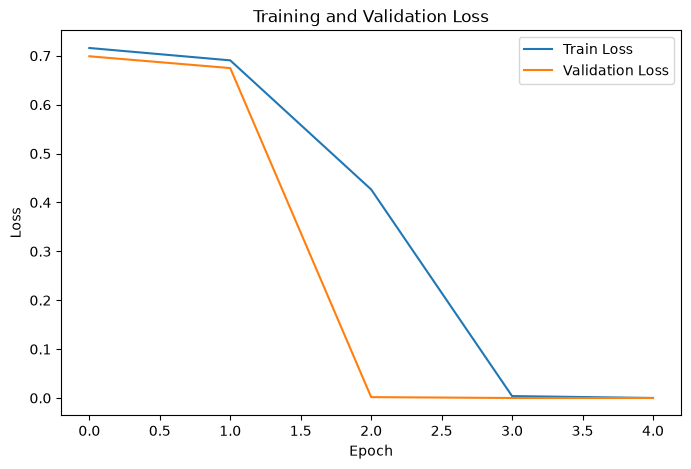

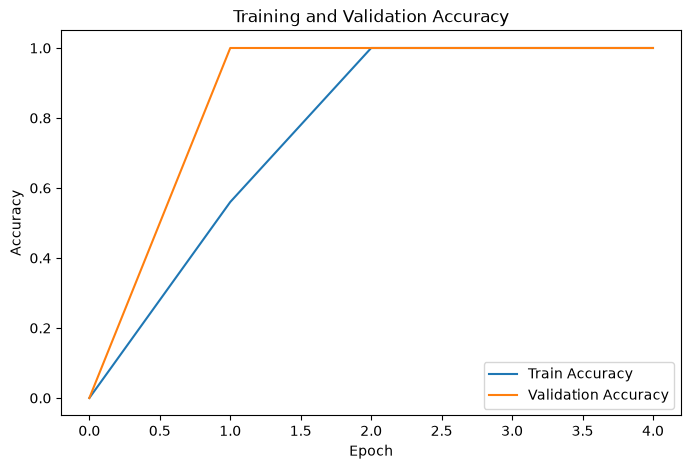

In [31]:
# ============================================================
# DAY 18: TRAINING HISTORY GRAPHS
# ============================================================

import matplotlib.pyplot as plt

# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.show()


# Plot training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(train_accs, label="Train Accuracy")
plt.plot(val_accs, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")

plt.legend()
plt.show()

In [32]:
# ============================================================
# DAY 19: CUSTOM CNN - TEST SET EVALUATION
# ============================================================

import torch

model.eval()

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        # Convert logits into probabilities
        probabilities = torch.sigmoid(outputs)

        # Convert probabilities into 0 or 1 predictions
        predictions = (probabilities >= 0.5).int()

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy().flatten())
        all_probabilities.extend(probabilities.cpu().numpy().flatten())


print("Test samples:", len(all_labels))
print("Predictions:", len(all_predictions))
print("Probabilities:", len(all_probabilities))

Test samples: 12321
Predictions: 12321
Probabilities: 12321


In [33]:
# ============================================================
# DAY 20: CUSTOM CNN - PERFORMANCE METRICS
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Calculate evaluation metrics
accuracy = accuracy_score(
    all_labels,
    all_predictions
)

precision = precision_score(
    all_labels,
    all_predictions,
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    zero_division=0
)

# Display results
print("Custom CNN Test Results")
print("------------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

Custom CNN Test Results
------------------------
Accuracy : 0.1389
Precision: 0.0000
Recall   : 0.0000
F1-Score : 0.0000


In [34]:
# ============================================================
# DAY 20 CHECK: LABEL AND PREDICTION DISTRIBUTION
# ============================================================

from collections import Counter

print("Actual labels:")
print(Counter(all_labels))

print("\nPredicted labels:")
print(Counter(all_predictions))

Actual labels:
Counter({np.int64(1): 10610, np.int64(0): 1711})

Predicted labels:
Counter({np.int32(0): 12321})


Confusion Matrix:
[[ 1711     0]
 [10610     0]]

ROC-AUC: 0.4700


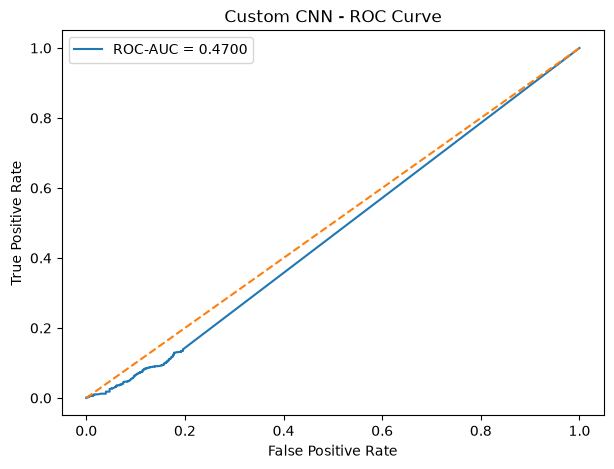

In [35]:
# ============================================================
# DAY 21: CONFUSION MATRIX + ROC-AUC + ROC CURVE
# ============================================================

from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Confusion Matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    all_labels,
    all_predictions
)

print("Confusion Matrix:")
print(cm)


# ------------------------------------------------------------
# 2. ROC-AUC Score
# ------------------------------------------------------------

roc_auc = roc_auc_score(
    all_labels,
    all_probabilities
)

print(f"\nROC-AUC: {roc_auc:.4f}")


# ------------------------------------------------------------
# 3. ROC Curve
# ------------------------------------------------------------

fpr, tpr, thresholds = roc_curve(
    all_labels,
    all_probabilities
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {roc_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Custom CNN - ROC Curve")

plt.legend()
plt.show()
